# Daily Sales Forecasting: from Feature-Engineered XGBoost to Prophet

A 90-day forecast for a synthetic daily sales series (2021-01 → 2024-06) with trend, weekly and yearly seasonality and holiday/closure days. The notebook builds the forecast iteratively:

1. **Naive XGBoost** on the timestamp alone, then calendar features (day of week, month, year).
2. **Autoregressive features**: 1, 7 and 30-day lags (the *AR* part of ARIMA).
3. **Moving-average features**: 7-day rolling mean/std plus cyclical seasonality (the *MA* part).
4. **Year-over-year memory**: a 365-day lag and a last-year-zero-sales flag for closures.
5. **Prophet** as a seasonality-aware benchmark.


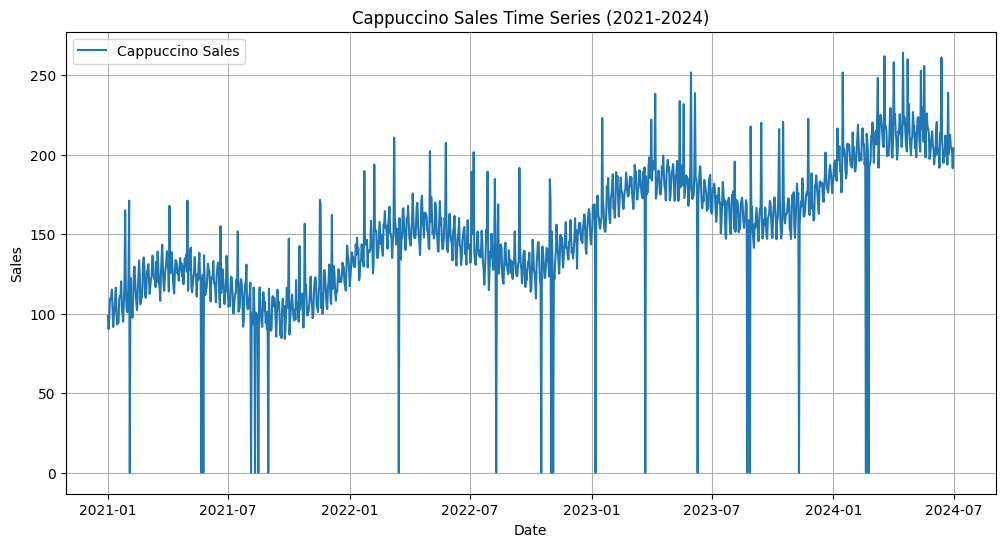

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set the date range for the time series
date_range = pd.date_range(start='2021-01-01', end='2024-06-30', freq='D')

# Initialize random seed for reproducibility
np.random.seed(42)

# Create a basic trend (e.g., sales growing over time slightly)
trend = np.linspace(100, 200, len(date_range)) # Linear growth from 100 to 200 units

# Add weekly seasonality (higher sales on weekends)
weekly_seasonality = 10 * np.sin(2 * np.pi * date_range.dayofweek / 7)

# Add yearly seasonality (spikes during specific times of the year)
day_of_year = date_range.dayofyear
yearly_seasonality = 20 * np.sin(2 * np.pi * day_of_year / 365)

# Simulate random noise
noise = np.random.normal(0, 5, len(date_range))

# Simulate promotions (random peaks)
promo_days = np.random.choice(date_range, size=50, replace=False)
promo_effect = np.zeros(len(date_range))
promo_effect[np.isin(date_range, promo_days)] = 50

# Simulate stockouts (zero sales on random days)
stockout_days = np.random.choice(date_range, size=20, replace=False)
stockout_effect = np.ones(len(date_range))
stockout_effect[np.isin(date_range, stockout_days)] = 0

# Combine all factors to create the final sales series
sales = trend + weekly_seasonality + yearly_seasonality + noise + promo_effect
sales = np.array(sales) # Convert to numpy array for manipulation
sales = sales * stockout_effect # Apply stockout effect

# Ensure no negative sales
sales[sales < 0] = 0

# Create DataFrame
df = pd.DataFrame({'Date': date_range, 'Sales': sales})

# Plot the time series
plt.figure(figsize=(12, 6))
plt.plot(df['Date'], df['Sales'], label='Cappuccino Sales')
plt.title('Cappuccino Sales Time Series (2021-2024)')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.grid(True)
plt.legend()
plt.show()

first creating an empty dataframe for future dates
then splitting my current actual data to train and test so that I can asses if the model is performing well on unseen data.
and after I am happy with the performance of the model.


In [62]:
df.tail()

,Date,Sales
1272,2024-06-26,205.521965
1273,2024-06-27,203.725951
1274,2024-06-28,202.430356
1275,2024-06-29,191.397304
1276,2024-06-30,203.950473


In [63]:
# set the index to the date column
#convert date column to datetime
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.head()

,Sales
Date,
2021-01-01,98.489000
2021-01-02,90.326202
2021-01-03,96.609261
2021-01-04,109.226308
2021-01-05,108.680324


In [64]:
# create a future df for teh next 90 days
future_dates = pd.date_range(start='2024-07-01', end='2024-09-28', freq='D')
future_df = pd.DataFrame(index=future_dates)

In [65]:
future_df['Sales'] = np.nan  # Initialize future sales with NaN

In [66]:
future_df.head()

,Sales
2024-07-01,NaN
2024-07-02,NaN
2024-07-03,NaN
2024-07-04,NaN
2024-07-05,NaN


In [67]:
# create the xgboost model
import xgboost as xgb   

xgb_model = xgb.XGBRegressor()
# Fit the model on the training data
xgb_model.fit(df.index.astype('int64').values.reshape(-1, 1), df['Sales'])


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [68]:
# predict future sales
future_df['Sales'] = xgb_model.predict(future_df.index.astype('int64').values.reshape(-1, 1))

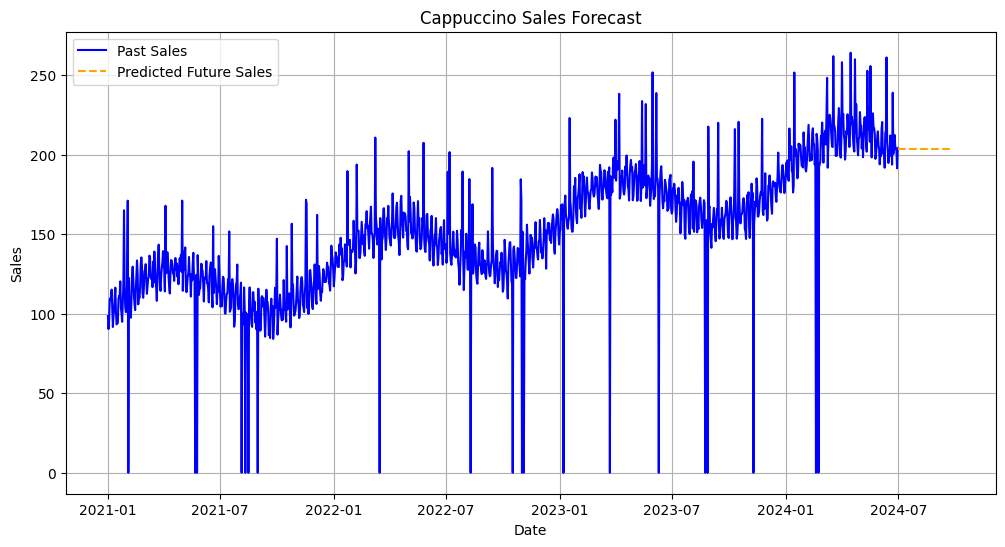

In [69]:
#plot the future sales with the past sales
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Sales'], label='Past Sales', color='blue')
plt.plot(future_df.index, future_df['Sales'], label='Predicted Future Sales',
            color='orange', linestyle='--')
plt.title('Cappuccino Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()


In [70]:
# create feautres like day of the week, month, year, etc.
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month
df['Year'] = df.index.year
# create season feature
df['Season'] = df['Month'].apply(lambda x: 'Winter' if (x >=
    12 or x <= 2) else 'Spring' if (x >= 3 and x <= 5) else 'Summer' if (x >= 6 and x <= 8) else 'Fall')


In [71]:
df.head()

,Sales,DayOfWeek,Month,Year,Season
Date,,,,,
2021-01-01,98.489000,4,1,2021,Winter
2021-01-02,90.326202,5,1,2021,Winter
2021-01-03,96.609261,6,1,2021,Winter
2021-01-04,109.226308,0,1,2021,Winter
2021-01-05,108.680324,1,1,2021,Winter


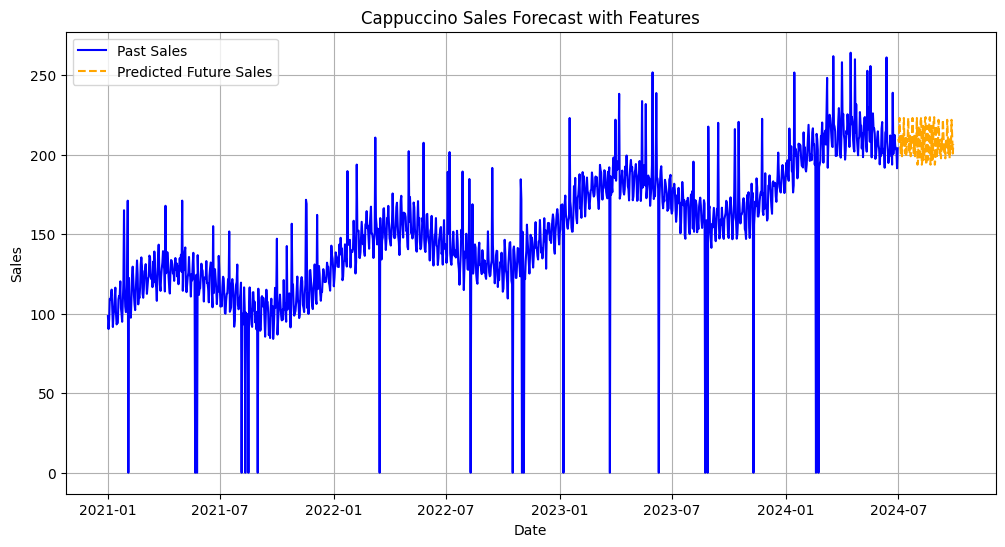

In [72]:
# fit the model again with the new features
xgb_model = xgb.XGBRegressor()
xgb_model.fit(df[['DayOfWeek', 'Month', 'Year']], df['Sales'])
# predict future sales with the new features
future_df['DayOfWeek'] = future_df.index.dayofweek
future_df['Month'] = future_df.index.month
future_df['Year'] = future_df.index.year
future_df['Season'] = future_df['Month'].apply(lambda x: 'Winter' if (x >=
    12 or x <= 2) else 'Spring' if (x >= 3 and x <= 5) else 'Summer' if (x >= 6 and x <= 8) else 'Fall')
future_df['Sales'] = xgb_model.predict(future_df[['DayOfWeek', 'Month', 'Year']])
# Plot the updated forecast
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Sales'], label='Past Sales', color='blue')
plt.plot(future_df.index, future_df['Sales'], label='Predicted Future Sales',
            color='orange', linestyle='--')
plt.title('Cappuccino Sales Forecast with Features')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [73]:
# feature importance
importances = xgb_model.feature_importances_
# Create a DataFrame for feature importances
feature_importances = pd.DataFrame({'Feature': ['DayOfWeek', 'Month', 'Year'], 'Importance': importances})
# Sort the DataFrame by importance
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)
# Print the feature importances
print(feature_importances)

     Feature  Importance
2       Year    0.895516
1      Month    0.065638
0  DayOfWeek    0.038845


## Iteration 1: lag features

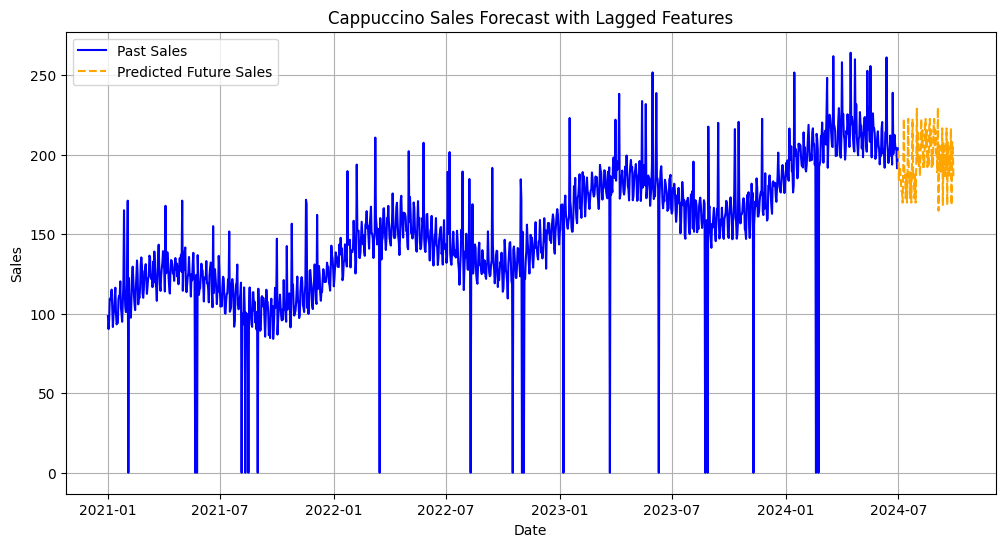

In [74]:
# create a lagged feature for sales
df['Lagged_Sales_1'] = df['Sales'].shift(1)
df['Lagged_Sales_7'] = df['Sales'].shift(7)
df['Lagged_Sales_30'] = df['Sales'].shift(30)
# fit the model again with the lagged features
xgb_model = xgb.XGBRegressor()
xgb_model.fit(df[['Lagged_Sales_1', 'Lagged_Sales_7', 'Lagged_Sales_30', 'DayOfWeek', 'Month', 'Year']], df['Sales'])
# predict future sales with the lagged features
future_df['Lagged_Sales_1'] = future_df['Sales'].shift(1)
future_df['Lagged_Sales_7'] = future_df['Sales'].shift(7)
future_df['Lagged_Sales_30'] = future_df['Sales'].shift(30)
future_df['Sales'] = xgb_model.predict(future_df[['Lagged_Sales_1', 'Lagged_Sales_7', 'Lagged_Sales_30', 'DayOfWeek', 'Month', 'Year']])
# Plot the final forecast with lagged features
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Sales'], label='Past Sales', color='blue')
plt.plot(future_df.index, future_df['Sales'], label='Predicted Future Sales',
            color='orange', linestyle='--')
plt.title('Cappuccino Sales Forecast with Lagged Features')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()



### After using the lagged sales for the day before, 7 days before and 30 days before, the forecast is definitely improved. The downwards trend is much more visible and the AR (AutoRegressive) element of ARIMA is incorporated into this model. This way the model takes consideration of the past sales behaviour and makes the prediction more realistic when compared to the seasonal trend that is evident in the previous sales' data.

## Iteration 2

#### Incorporating the MA element to the xgboost model and also taking consideration of seasonality 

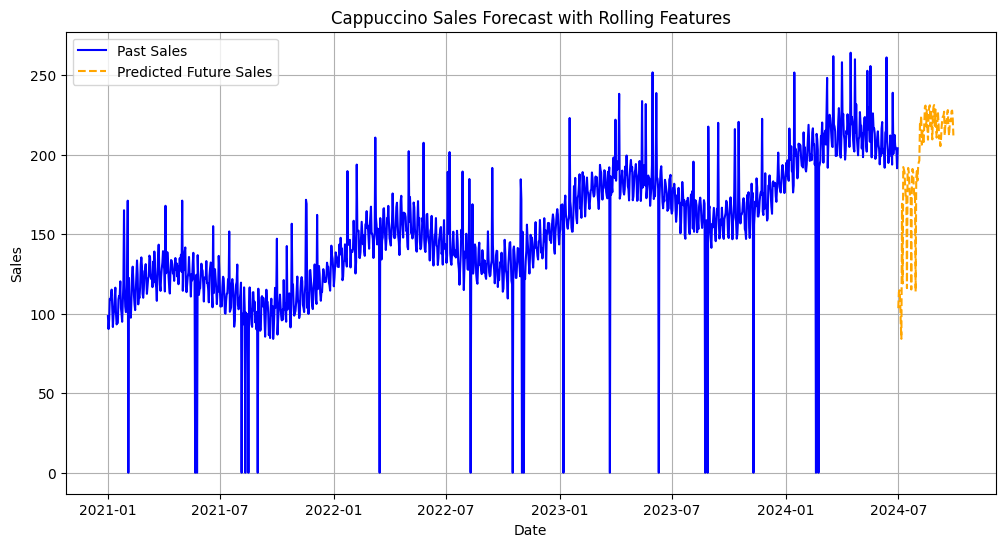

In [75]:
# now use the rolling mean and rolling std to create features
df['Rolling_Mean_7'] = df['Sales'].rolling(window=7).mean()
df['Rolling_Std_7'] = df['Sales'].rolling(window=7).std()
# use the cyclical seasonality and drop my string coded Season feature
df.drop('Season', axis=1, inplace=True)
future_df.drop('Season', axis=1, inplace=True)
df['Cyclical_Seasonality'] = np.sin(2 * np.pi * df.index.dayofyear / 365)
# fit the model again with the new features
xgb_model = xgb.XGBRegressor()
xgb_model.fit(df.drop('Sales', axis=1), df['Sales'])
# predict future sales with the new features
future_df['Rolling_Mean_7'] = future_df['Sales'].rolling(window=7).mean()
future_df['Rolling_Std_7'] = future_df['Sales'].rolling(window=7).std()
future_df['Cyclical_Seasonality'] = np.sin(2 * np.pi * future_df.index.dayofyear / 365)
future_df['Sales'] = xgb_model.predict(future_df.drop('Sales', axis=1))
# Plot the final forecast with rolling features
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Sales'], label='Past Sales', color='blue')
plt.plot(future_df.index, future_df['Sales'], label='Predicted Future Sales',
            color='orange', linestyle='--')
plt.title('Cappuccino Sales Forecast with Rolling Features')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()



### After incorporating the rolling mean (basically the MA element of ARIMA) and the rolling standard deviation and the cyclical seasonality, the model captured the last years trend more effectively and it even captured the decreasing sales trend after July for each year. Overall the forecast is now more dynamically capturing the seasonality and the trend of the sales data.

## Iteration 3

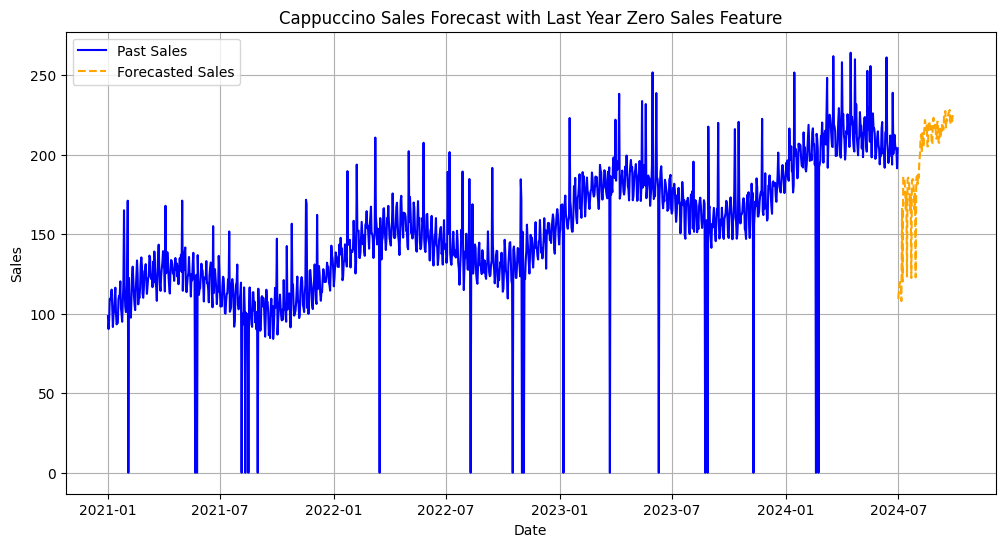

In [76]:
# create a 365 lagged feature for sales to capture the zero sales days
df['Lagged_Sales_365'] = df['Sales'].shift(365)
# create a feature to indicate if the last year's sales was zero
df['Is_Last_Year_Zero_Sales'] = df['Lagged_Sales_365'] == 0
# fill the NaN values with 0 for the lagged feature
df['Lagged_Sales_365'] = df['Lagged_Sales_365'].fillna(0)
# do the same for the future df
future_df['Lagged_Sales_365'] = future_df['Sales'].shift(365)
future_df['Is_Last_Year_Zero_Sales'] = future_df['Lagged_Sales_365'] == 0
future_df['Lagged_Sales_365'] = future_df['Lagged_Sales_365'].fillna(0)
# fit the model again with the new features
xgb_model = xgb.XGBRegressor()
xgb_model.fit(df.drop('Sales', axis=1), df['Sales'])
# predict future sales with the new features
future_df['Sales'] = xgb_model.predict(future_df.drop('Sales', axis=1))
# Plot the final forecast with last year's zero sales feature
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Sales'], label='Past Sales', color='blue')
plt.plot(future_df.index, future_df['Sales'], label='Forecasted Sales', color='orange', linestyle='--')
plt.title('Cappuccino Sales Forecast with Last Year Zero Sales Feature')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()


### In this third and last iteration I introduced a Lagged_Sales_365 feature and a binary indicator for the model to capture the day from last year if this day was a holiday or store closure day. This slightly improved the models performance visually especially the variance after the drop. To further enhance the accuracy I will use prophet afterwards.

### Iteration 4

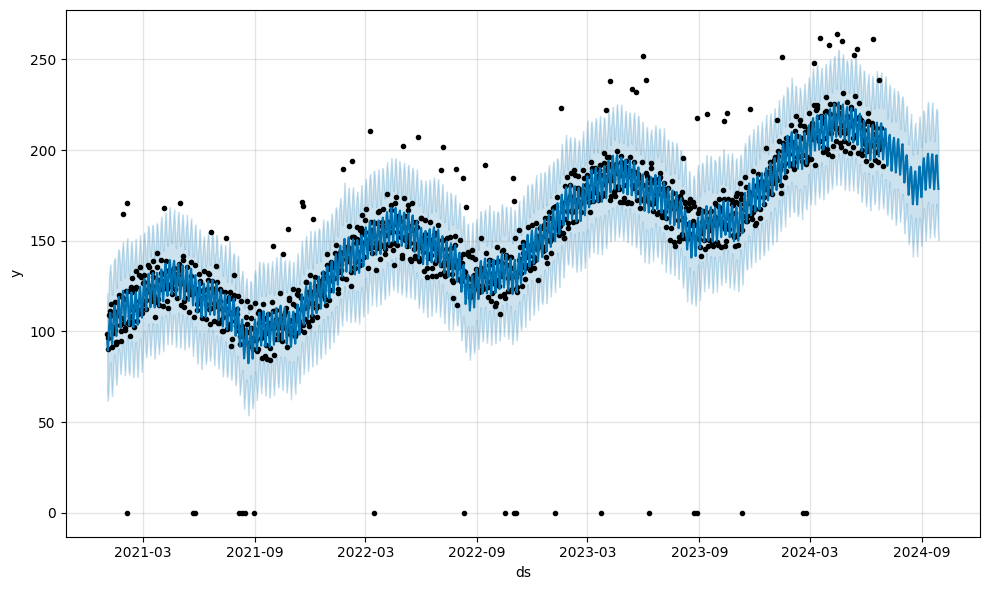

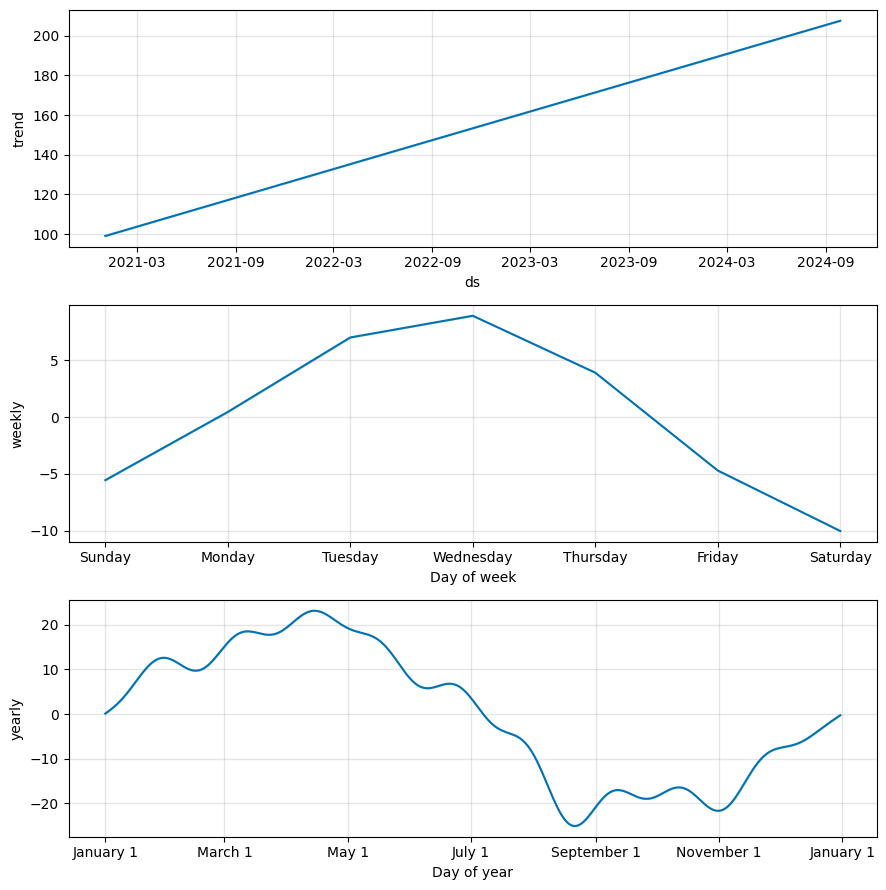

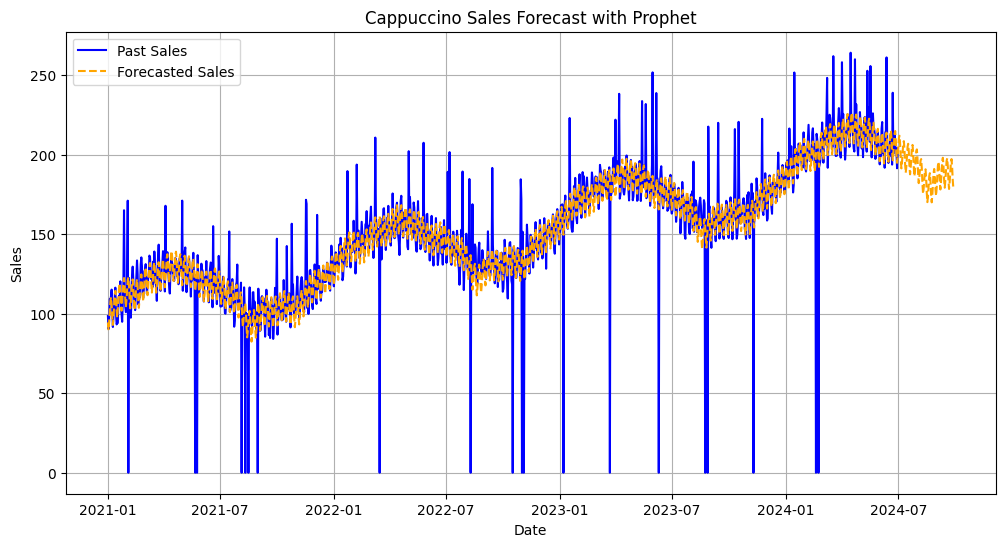

In [78]:
# use prophet to forecast the sales
from prophet import Prophet
# now use my data and future data to fit the model
prophet_df = df.reset_index().rename(columns={'Date': 'ds', 'Sales': 'y'})
model = Prophet()

# fit the model
model.fit(prophet_df)

# create a future dataframe for prophet for 90 days
future_prophet_df = model.make_future_dataframe(periods=90,freq='D')
# make predictions
forecast = model.predict(future_prophet_df)
# Plot the forecast
fig = model.plot(forecast)
# Plot the forecast components
fig2 = model.plot_components(forecast)
# Plot the forecast with the original data
plt.figure(figsize=(12, 6))
plt.plot(prophet_df['ds'], prophet_df['y'], label='Past Sales', color='blue')
plt.plot(forecast['ds'], forecast['yhat'], label='Forecasted Sales', color='orange', linestyle='--')
plt.title('Cappuccino Sales Forecast with Prophet')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()


### Prophet produced a smooth forecast which captured the trend definitely better. The seasonal patterns are much more visible and realistic. Unlike XGBoost Prophet is much more suited to make forecasts especially with datasets with seasonality.